# Tax Outcome Prediction Using Machine Learning
**End-to-end Jupyter project:** synthetic data → EDA → preprocessing → regression and classification → evaluation → new predictions.

> **Educational demonstration only.** The dataset and its tax-generation formula are fictional, not IRS rules. Predictions must **not** be used for filing, tax planning, or determining tax liability. Real-world tax estimates require tax-year-specific rules, complete financial information, and professional verification.

**Definitions:** `net_refund = withholding - illustrative_liability`; positive = refund, negative = amount owed. We predict net refund using inputs known before the final outcome. This notebook does not use actual bank-account records or sensitive identifiers.

## 1. Environment and reproducibility
Run this cell first. If a package is missing, install it in a separate cell using `%pip install pandas numpy scikit-learn matplotlib seaborn` and restart the kernel.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `import sys, warnings` | Imports the library components needed for this analysis. |
| 2 | `import numpy as np` | Imports the library components needed for this analysis. |
| 3 | `import pandas as pd` | Imports the library components needed for this analysis. |
| 4 | `import matplotlib` | Imports the library components needed for this analysis. |
| 5 | `matplotlib.use('Agg')  # Saves figures reliably even if Jupyter inline font rendering is broken` | Continues the preceding expression or configuration. |
| 6 | `import matplotlib.pyplot as plt` | Imports the library components needed for this analysis. |
| 7 | `from IPython.display import display, Image` | Imports the library components needed for this analysis. |
| 8 | `from pathlib import Path` | Imports the library components needed for this analysis. |
| 9 | `from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate` | Imports the library components needed for this analysis. |
| 10 | `from sklearn.compose import ColumnTransformer` | Imports the library components needed for this analysis. |
| 11 | `from sklearn.pipeline import Pipeline` | Imports the library components needed for this analysis. |
| 12 | `from sklearn.preprocessing import OneHotEncoder, StandardScaler` | Imports the library components needed for this analysis. |
| 13 | `from sklearn.impute import SimpleImputer` | Imports the library components needed for this analysis. |
| 14 | `from sklearn.linear_model import Ridge, LogisticRegression` | Imports the library components needed for this analysis. |
| 15 | `from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier` | Imports the library components needed for this analysis. |
| 16 | `from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay, roc_auc_score` | Imports the library components needed for this analysis. |
| 18 | `RANDOM_STATE = 42` | Assigns or updates `RANDOM_STATE` for use in subsequent steps. |
| 19 | `rng = np.random.default_rng(RANDOM_STATE)` | Assigns or updates `rng` for use in subsequent steps. |
| 20 | `OUTPUT = Path('tax_project_outputs'); OUTPUT.mkdir(exist_ok=True)` | Assigns or updates `OUTPUT` for use in subsequent steps. |
| 21 | `print('Python:', sys.version.split()[0], '\| sklearn loaded')` | Prints a result or diagnostic message. |
| 23 | `def save_chart(filename):` | Defines a reusable helper function. |
| 24 | `path = OUTPUT / filename` | Assigns or updates `path` for use in subsequent steps. |
| 25 | `plt.tight_layout(); plt.savefig(path, dpi=130, bbox_inches='tight')` | Assigns or updates `plt.tight_layout(); plt.savefig(path, dpi` for use in subsequent steps. |
| 26 | `plt.close()` | Continues the preceding expression or configuration. |
| 27 | `display(Image(filename=str(path)))` | Displays a table or image in the notebook. |


In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # Saves figures reliably even if Jupyter inline font rendering is broken
import matplotlib.pyplot as plt
from IPython.display import display, Image
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay, roc_auc_score

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
OUTPUT = Path('tax_project_outputs'); OUTPUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| sklearn loaded')

def save_chart(filename):
    path = OUTPUT / filename
    plt.tight_layout(); plt.savefig(path, dpi=130, bbox_inches='tight')
    plt.close()
    display(Image(filename=str(path)))


Python: 3.13.5 | sklearn loaded


## 2. Generate a synthetic dataset
The fictional outcome is a simplified nonlinear function of income, deductions, credits, and withholding plus random variation. **It is not a tax law model.** The random variation intentionally makes the prediction task nontrivial.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `N = 4000` | Assigns or updates `N` for use in subsequent steps. |
| 2 | `status = rng.choice(['Single','Married filing jointly','Head of household'], size=N, p=[.53,.34,.13])` | Generates reproducible simulated values with a random number generator. |
| 3 | `income = np.clip(rng.lognormal(np.log(68000), .62, N), 12000, 300000)` | Generates reproducible simulated values with a random number generator. |
| 4 | `other_income = np.where(rng.random(N)<.28, rng.gamma(2, 2400, N), 0)` | Generates reproducible simulated values with a random number generator. |
| 5 | `dependents = np.clip(rng.poisson(.85, N), 0, 5)` | Generates reproducible simulated values with a random number generator. |
| 6 | `deduction = np.where(status=='Married filing jointly', 28000, np.where(status=='Head of household', 21000, 14000))` | Selects values based on a condition. |
| 7 | `additional_deduction = rng.gamma(1.8, 1700, N)` | Generates reproducible simulated values with a random number generator. |
| 8 | `withholding_rate = np.clip(rng.normal(.14, .055, N), .015, .31)` | Generates reproducible simulated values with a random number generator. |
| 9 | `withholding = income * withholding_rate` | Assigns or updates `withholding` for use in subsequent steps. |
| 11 | `# Illustrative, deliberately fictional calculation (NOT real tax brackets or credits)` | Documents the purpose or limitation of the next calculation. |
| 12 | `taxable_proxy = np.maximum(income + other_income - deduction - additional_deduction, 0)` | Constrains values within the specified range. |
| 13 | `illustrative_liability = (.11 * np.minimum(taxable_proxy, 55000)` | Assigns or updates `illustrative_liability` for use in subsequent steps. |
| 14 | `+ .19 * np.clip(taxable_proxy-55000, 0, 85000)` | Constrains values within the specified range. |
| 15 | `+ .27 * np.maximum(taxable_proxy-140000, 0)` | Constrains values within the specified range. |
| 16 | `- 650 * dependents)` | Continues the calculation or function call from the previous line. |
| 17 | `illustrative_liability = np.maximum(illustrative_liability, 0)` | Constrains values within the specified range. |
| 18 | `net_refund = withholding - illustrative_liability + rng.normal(0, 850, N)` | Generates reproducible simulated values with a random number generator. |
| 20 | `df = pd.DataFrame({` | Creates a pandas table from the supplied records or arrays. |
| 21 | `'annual_income': income.round(2), 'other_income': other_income.round(2),` | Defines a named field, model, or setting in a collection. |
| 22 | `'filing_status': status, 'dependents': dependents,` | Defines a named field, model, or setting in a collection. |
| 23 | `'additional_deductions': additional_deduction.round(2),` | Defines a named field, model, or setting in a collection. |
| 24 | `'tax_withheld': withholding.round(2),` | Defines a named field, model, or setting in a collection. |
| 25 | `'net_refund': net_refund.round(2)` | Continues the preceding expression or configuration. |
| 26 | `})` | Closes the preceding data structure or function call. |
| 27 | `df['outcome'] = np.where(df.net_refund>=0, 'Refund', 'Owe')` | Selects values based on a condition. |
| 28 | `# Demonstrate missing-value handling in predictors` | Documents the purpose or limitation of the next calculation. |
| 29 | `for col, rate in [('other_income',.04), ('additional_deductions',.05)]:` | Loops over the specified records, features, or models. |
| 30 | `df.loc[rng.random(N)<rate, col] = np.nan` | Generates reproducible simulated values with a random number generator. |
| 32 | `df.to_csv(OUTPUT/'synthetic_tax_data.csv', index=False)` | Exports results as a CSV file. |
| 33 | `display(df.head())` | Displays a table or image in the notebook. |
| 34 | `print('Rows:', len(df), ' \| Refund share:', round((df.outcome=='Refund').mean(), 3))` | Prints a result or diagnostic message. |


In [2]:
N = 4000
status = rng.choice(['Single','Married filing jointly','Head of household'], size=N, p=[.53,.34,.13])
income = np.clip(rng.lognormal(np.log(68000), .62, N), 12000, 300000)
other_income = np.where(rng.random(N)<.28, rng.gamma(2, 2400, N), 0)
dependents = np.clip(rng.poisson(.85, N), 0, 5)
deduction = np.where(status=='Married filing jointly', 28000, np.where(status=='Head of household', 21000, 14000))
additional_deduction = rng.gamma(1.8, 1700, N)
withholding_rate = np.clip(rng.normal(.14, .055, N), .015, .31)
withholding = income * withholding_rate

# Illustrative, deliberately fictional calculation (NOT real tax brackets or credits)
taxable_proxy = np.maximum(income + other_income - deduction - additional_deduction, 0)
illustrative_liability = (.11 * np.minimum(taxable_proxy, 55000)
                          + .19 * np.clip(taxable_proxy-55000, 0, 85000)
                          + .27 * np.maximum(taxable_proxy-140000, 0)
                          - 650 * dependents)
illustrative_liability = np.maximum(illustrative_liability, 0)
net_refund = withholding - illustrative_liability + rng.normal(0, 850, N)

df = pd.DataFrame({
    'annual_income': income.round(2), 'other_income': other_income.round(2),
    'filing_status': status, 'dependents': dependents,
    'additional_deductions': additional_deduction.round(2),
    'tax_withheld': withholding.round(2),
    'net_refund': net_refund.round(2)
})
df['outcome'] = np.where(df.net_refund>=0, 'Refund', 'Owe')
# Demonstrate missing-value handling in predictors
for col, rate in [('other_income',.04), ('additional_deductions',.05)]:
    df.loc[rng.random(N)<rate, col] = np.nan

df.to_csv(OUTPUT/'synthetic_tax_data.csv', index=False)
display(df.head())
print('Rows:', len(df), ' | Refund share:', round((df.outcome=='Refund').mean(), 3))

,annual_income,other_income,filing_status,dependents,additional_deductions,tax_withheld,net_refund,outcome
0,35670.90,0.00,Married filing jointly,1,4275.88,2257.37,3256.07,Refund
1,26885.26,0.00,Single,0,2221.14,4319.72,3032.68,Refund
2,157293.88,0.00,Married filing jointly,0,2174.45,21326.78,1062.14,Refund
3,300000.00,2632.49,Married filing jointly,0,4395.55,59717.35,2028.86,Refund
4,50629.95,7214.43,Single,0,NaN,9474.67,4888.91,Refund


Rows: 4000  | Refund share: 0.803


## 3. Exploratory data analysis

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `display(df.describe(include='all').T)` | Displays a table or image in the notebook. |
| 2 | `print('Missing values:')` | Prints a result or diagnostic message. |
| 3 | `display(df.isna().sum().to_frame('missing_count'))` | Displays a table or image in the notebook. |
| 4 | `print('Outcome counts:')` | Prints a result or diagnostic message. |
| 5 | `display(df.outcome.value_counts().to_frame('count'))` | Displays a table or image in the notebook. |


In [3]:
display(df.describe(include='all').T)
print('Missing values:')
display(df.isna().sum().to_frame('missing_count'))
print('Outcome counts:')
display(df.outcome.value_counts().to_frame('count'))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
annual_income,4000.0,NaN,NaN,NaN,81760.806667,52965.864524,12000.0,45063.735,67098.43,102554.905,300000.0
other_income,3854.0,NaN,NaN,NaN,1362.754961,2903.437563,0.0,0.0,0.0,1295.485,23350.7
filing_status,4000,3,Single,2146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,4000.0,NaN,NaN,NaN,0.86925,0.930791,0.0,0.0,1.0,1.0,5.0
additional_deductions,3801.0,NaN,NaN,NaN,3030.311284,2313.274889,31.81,1338.99,2439.56,4088.63,16347.46
tax_withheld,4000.0,NaN,NaN,NaN,11443.449742,9209.982617,180.0,5348.1875,8887.89,14546.185,75797.6
net_refund,4000.0,NaN,NaN,NaN,3123.474252,6335.608488,-47981.1,900.565,3720.135,6403.9725,30986.82
outcome,4000,2,Refund,3213,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:


,missing_count
annual_income,0
other_income,146
filing_status,0
dependents,0
additional_deductions,199
tax_withheld,0
net_refund,0
outcome,0


Outcome counts:


,count
outcome,
Refund,3213
Owe,787


### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `fig, ax = plt.subplots(figsize=(7,4))` | Creates a figure and axes for the visualization. |
| 2 | `df['outcome'].value_counts().plot.bar(ax=ax)` | Draws or labels part of the chart. |
| 3 | `ax.set(title='Synthetic tax outcomes', xlabel='Outcome', ylabel='Taxpayers')` | Draws or labels part of the chart. |
| 4 | `save_chart('01_outcome_distribution.png')` | Saves the chart as an image and displays it. |
| 6 | `fig, ax = plt.subplots(figsize=(7,4))` | Creates a figure and axes for the visualization. |
| 7 | `ax.hist(df['net_refund'], bins=55)` | Draws or labels part of the chart. |
| 8 | `ax.set(title='Synthetic net refund distribution', xlabel='Net refund ($): positive = refund', ylabel='Count')` | Draws or labels part of the chart. |
| 9 | `save_chart('02_net_refund_distribution.png')` | Saves the chart as an image and displays it. |
| 11 | `fig, ax = plt.subplots(figsize=(7,4))` | Creates a figure and axes for the visualization. |
| 12 | `df.groupby('filing_status')['net_refund'].median().sort_values().plot.barh(ax=ax)` | Draws or labels part of the chart. |
| 13 | `ax.set(title='Median synthetic net refund by filing status', xlabel='Median net refund ($)')` | Draws or labels part of the chart. |
| 14 | `save_chart('03_filing_status.png')` | Saves the chart as an image and displays it. |
| 16 | `fig, ax = plt.subplots(figsize=(7,4))` | Creates a figure and axes for the visualization. |
| 17 | `ax.scatter(df['annual_income'], df['net_refund'], s=7, alpha=.2)` | Draws or labels part of the chart. |
| 18 | `ax.set(title='Income vs synthetic net refund', xlabel='Annual income ($)', ylabel='Net refund ($)')` | Draws or labels part of the chart. |
| 19 | `save_chart('04_income_scatter.png')` | Saves the chart as an image and displays it. |


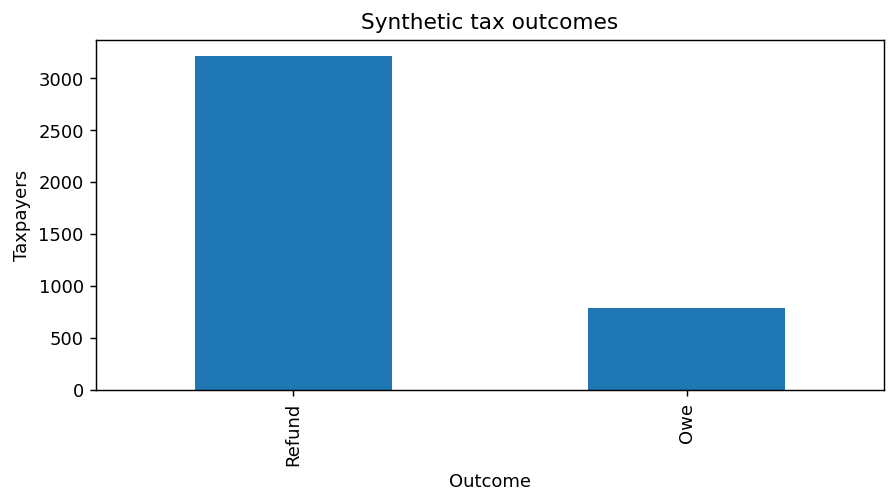

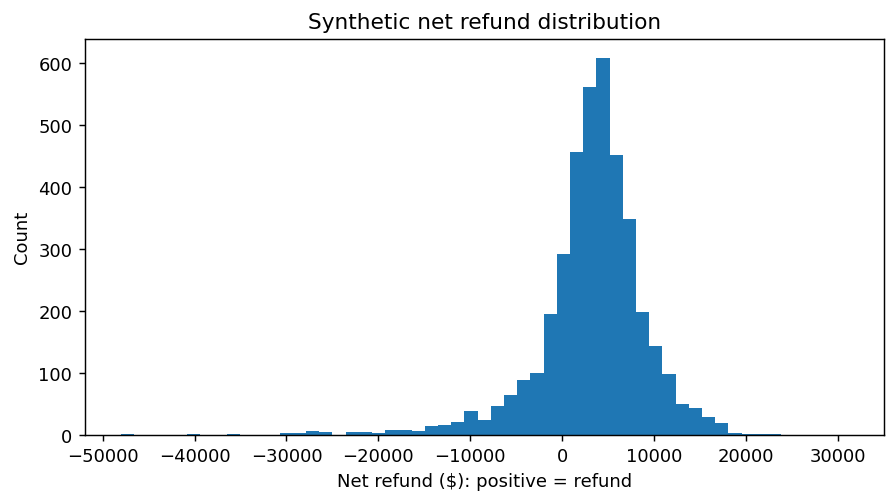

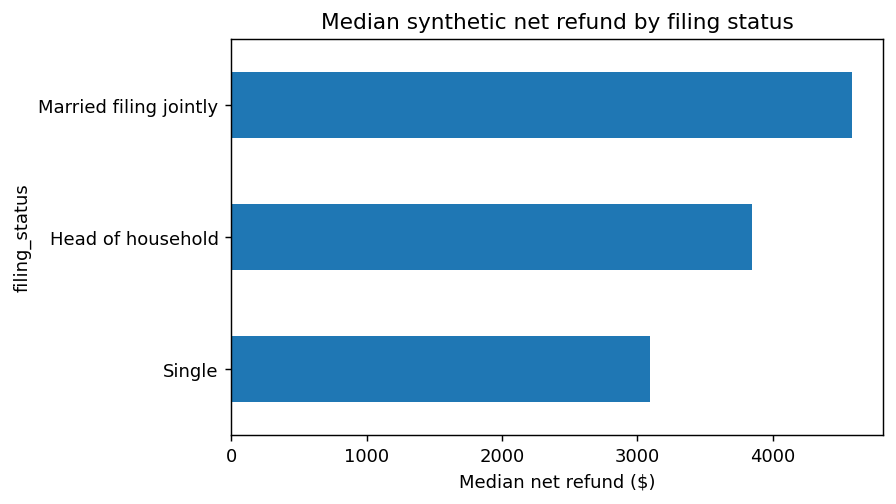

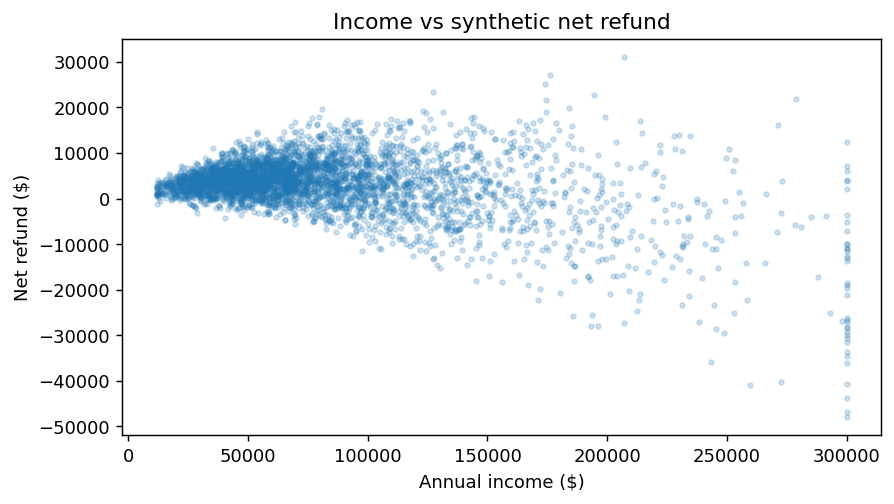

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
df['outcome'].value_counts().plot.bar(ax=ax)
ax.set(title='Synthetic tax outcomes', xlabel='Outcome', ylabel='Taxpayers')
save_chart('01_outcome_distribution.png')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df['net_refund'], bins=55)
ax.set(title='Synthetic net refund distribution', xlabel='Net refund ($): positive = refund', ylabel='Count')
save_chart('02_net_refund_distribution.png')

fig, ax = plt.subplots(figsize=(7,4))
df.groupby('filing_status')['net_refund'].median().sort_values().plot.barh(ax=ax)
ax.set(title='Median synthetic net refund by filing status', xlabel='Median net refund ($)')
save_chart('03_filing_status.png')

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(df['annual_income'], df['net_refund'], s=7, alpha=.2)
ax.set(title='Income vs synthetic net refund', xlabel='Annual income ($)', ylabel='Net refund ($)')
save_chart('04_income_scatter.png')

## 4. Features, leakage prevention, and train/test split
We exclude `outcome` when predicting `net_refund`, and exclude `net_refund` when predicting `outcome`: using either as an input would leak the answer. We reserve 20% for final testing and choose models with cross-validation on the remaining 80%.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `FEATURES = ['annual_income','other_income','filing_status','dependents','additional_deductions','tax_withheld']` | Assigns or updates `FEATURES` for use in subsequent steps. |
| 2 | `X = df[FEATURES]` | Assigns or updates `X` for use in subsequent steps. |
| 3 | `y_reg = df['net_refund']` | Assigns or updates `y_reg` for use in subsequent steps. |
| 4 | `y_clf = (df['outcome']=='Refund').astype(int)` | Assigns or updates `y_clf` for use in subsequent steps. |
| 5 | `X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(` | Creates training and holdout partitions. |
| 6 | `X, y_reg, y_clf, test_size=.20, random_state=RANDOM_STATE, stratify=y_clf` | Assigns or updates `X, y_reg, y_clf, test_size` for use in subsequent steps. |
| 7 | `)` | Closes the preceding data structure or function call. |
| 8 | `num_cols = [c for c in FEATURES if c!='filing_status']` | Assigns or updates `num_cols` for use in subsequent steps. |
| 9 | `cat_cols = ['filing_status']` | Assigns or updates `cat_cols` for use in subsequent steps. |
| 11 | `def preprocessing():` | Defines a reusable helper function. |
| 12 | `return ColumnTransformer([` | Returns the constructed preprocessing or result object. |
| 13 | `('numeric', Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),` | Builds a sequence of preprocessing and modeling operations. |
| 14 | `('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),` | Builds a sequence of preprocessing and modeling operations. |
| 15 | `('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)` | Encodes categorical values as model-ready indicator columns. |
| 16 | `])` | Closes the preceding data structure or function call. |
| 17 | `print('Train:',len(X_train),' Test:',len(X_test))` | Prints a result or diagnostic message. |


In [5]:
FEATURES = ['annual_income','other_income','filing_status','dependents','additional_deductions','tax_withheld']
X = df[FEATURES]
y_reg = df['net_refund']
y_clf = (df['outcome']=='Refund').astype(int)
X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=.20, random_state=RANDOM_STATE, stratify=y_clf
)
num_cols = [c for c in FEATURES if c!='filing_status']
cat_cols = ['filing_status']

def preprocessing():
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
        ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                                 ('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
    ])
print('Train:',len(X_train),' Test:',len(X_test))

Train: 3200  Test: 800


## 5. Regression: predict dollar refund/amount owed
Compare a linear baseline and nonlinear alternatives using five-fold CV. Lower MAE/RMSE is better; higher R² is better. Cross-validation operates only on the training partition.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `regressors = {` | Assigns or updates `regressors` for use in subsequent steps. |
| 2 | `'Ridge': Ridge(alpha=10),` | Defines a named field, model, or setting in a collection. |
| 3 | `'Random Forest': RandomForestRegressor(n_estimators=140, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),` | Defines a named field, model, or setting in a collection. |
| 4 | `'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=140, max_leaf_nodes=15, learning_rate=.06, random_state=RANDOM_STATE)` | Assigns or updates `'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter` for use in subsequent steps. |
| 5 | `}` | Closes the preceding data structure or function call. |
| 6 | `reg_results=[]` | Assigns or updates `reg_results` for use in subsequent steps. |
| 7 | `for name, estimator in regressors.items():` | Loops over the specified records, features, or models. |
| 8 | `pipe = Pipeline([('preprocess',preprocessing()),('model',estimator)])` | Builds a sequence of preprocessing and modeling operations. |
| 9 | `cv = cross_validate(pipe, X_train, yr_train, cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),` | Evaluates the model using cross-validation on training data. |
| 10 | `scoring={'mae':'neg_mean_absolute_error','r2':'r2'}, n_jobs=1)` | Assigns or updates `scoring` for use in subsequent steps. |
| 11 | `reg_results.append({'model':name,'cv_mae':-cv['test_mae'].mean(),'cv_r2':cv['test_r2'].mean()})` | Continues the preceding expression or configuration. |
| 12 | `reg_table=pd.DataFrame(reg_results).sort_values('cv_mae')` | Creates a pandas table from the supplied records or arrays. |
| 13 | `display(reg_table)` | Displays a table or image in the notebook. |
| 14 | `reg_table.to_csv(OUTPUT/'regression_cv_results.csv',index=False)` | Exports results as a CSV file. |
| 15 | `best_reg_name=reg_table.iloc[0]['model']` | Assigns or updates `best_reg_name` for use in subsequent steps. |
| 16 | `best_reg=Pipeline([('preprocess',preprocessing()),('model',regressors[best_reg_name])])` | Builds a sequence of preprocessing and modeling operations. |
| 17 | `best_reg.fit(X_train,yr_train)` | Fits the model to the specified training data. |
| 18 | `reg_pred=best_reg.predict(X_test)` | Generates model predictions. |
| 19 | `print('Selected:',best_reg_name)` | Prints a result or diagnostic message. |
| 20 | `print('Holdout MAE:',round(mean_absolute_error(yr_test,reg_pred),2))` | Prints a result or diagnostic message. |
| 21 | `print('Holdout RMSE:',round(np.sqrt(mean_squared_error(yr_test,reg_pred)),2))` | Prints a result or diagnostic message. |
| 22 | `print('Holdout R2:',round(r2_score(yr_test,reg_pred),3))` | Prints a result or diagnostic message. |


In [6]:
regressors = {
    'Ridge': Ridge(alpha=10),
    'Random Forest': RandomForestRegressor(n_estimators=140, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=140, max_leaf_nodes=15, learning_rate=.06, random_state=RANDOM_STATE)
}
reg_results=[]
for name, estimator in regressors.items():
    pipe = Pipeline([('preprocess',preprocessing()),('model',estimator)])
    cv = cross_validate(pipe, X_train, yr_train, cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),
                        scoring={'mae':'neg_mean_absolute_error','r2':'r2'}, n_jobs=1)
    reg_results.append({'model':name,'cv_mae':-cv['test_mae'].mean(),'cv_r2':cv['test_r2'].mean()})
reg_table=pd.DataFrame(reg_results).sort_values('cv_mae')
display(reg_table)
reg_table.to_csv(OUTPUT/'regression_cv_results.csv',index=False)
best_reg_name=reg_table.iloc[0]['model']
best_reg=Pipeline([('preprocess',preprocessing()),('model',regressors[best_reg_name])])
best_reg.fit(X_train,yr_train)
reg_pred=best_reg.predict(X_test)
print('Selected:',best_reg_name)
print('Holdout MAE:',round(mean_absolute_error(yr_test,reg_pred),2))
print('Holdout RMSE:',round(np.sqrt(mean_squared_error(yr_test,reg_pred)),2))
print('Holdout R2:',round(r2_score(yr_test,reg_pred),3))

,model,cv_mae,cv_r2
2,Hist Gradient Boosting,926.664657,0.951455
1,Random Forest,1062.715199,0.939335
0,Ridge,1652.384709,0.872254


Selected: Hist Gradient Boosting
Holdout MAE: 923.04
Holdout RMSE: 1502.86
Holdout R2: 0.951


### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `fig, ax=plt.subplots(figsize=(6,5))` | Creates a figure and axes for the visualization. |
| 2 | `ax.scatter(yr_test,reg_pred,s=10,alpha=.3)` | Draws or labels part of the chart. |
| 3 | `lo=min(yr_test.min(),reg_pred.min()); hi=max(yr_test.max(),reg_pred.max())` | Assigns or updates `lo` for use in subsequent steps. |
| 4 | `ax.plot([lo,hi],[lo,hi],linestyle='--',color='black')` | Draws or labels part of the chart. |
| 5 | `ax.set(xlabel='Actual synthetic net refund ($)',ylabel='Predicted ($)',title='Holdout: actual vs predicted')` | Draws or labels part of the chart. |
| 6 | `save_chart('05_actual_vs_predicted.png')` | Saves the chart as an image and displays it. |
| 8 | `fig,ax=plt.subplots(figsize=(7,4))` | Creates a figure and axes for the visualization. |
| 9 | `ax.barh(reg_table['model'],reg_table['cv_mae'])` | Draws or labels part of the chart. |
| 10 | `ax.set(xlabel='5-fold CV mean absolute error ($)',title='Regression model comparison')` | Draws or labels part of the chart. |
| 11 | `save_chart('06_regression_comparison.png')` | Saves the chart as an image and displays it. |


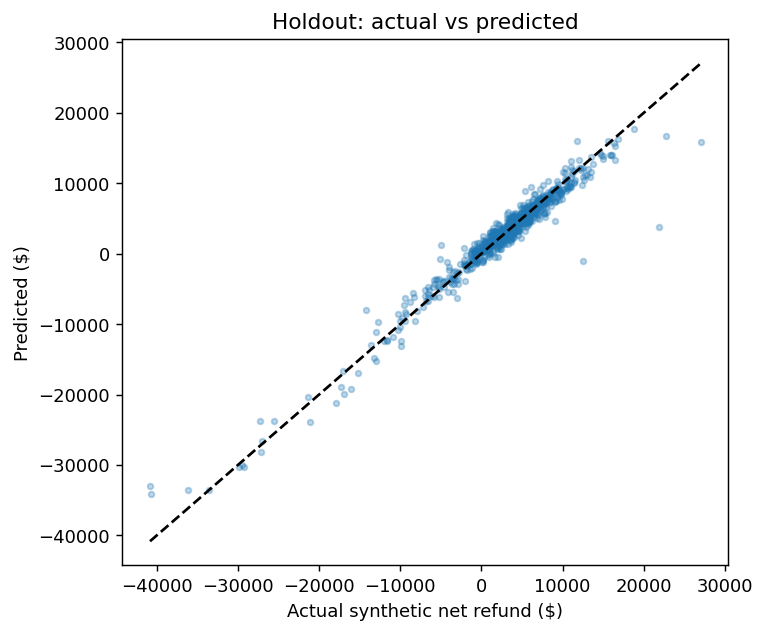

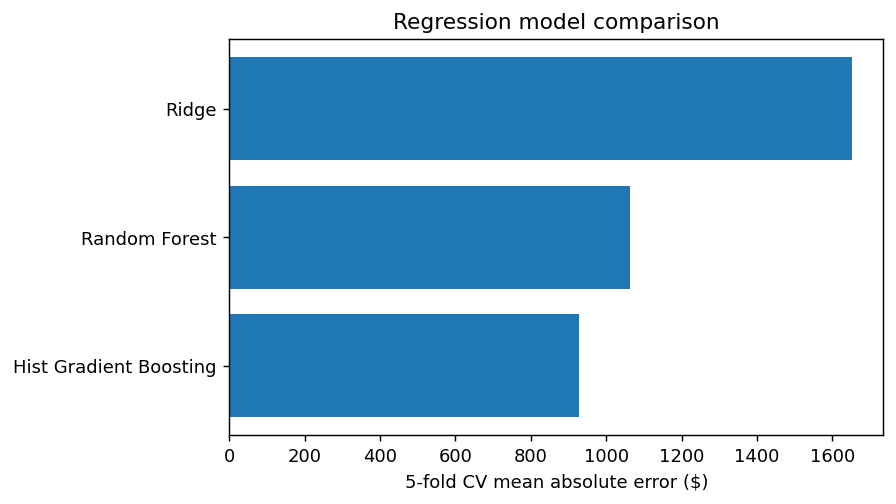

In [7]:
fig, ax=plt.subplots(figsize=(6,5))
ax.scatter(yr_test,reg_pred,s=10,alpha=.3)
lo=min(yr_test.min(),reg_pred.min()); hi=max(yr_test.max(),reg_pred.max())
ax.plot([lo,hi],[lo,hi],linestyle='--',color='black')
ax.set(xlabel='Actual synthetic net refund ($)',ylabel='Predicted ($)',title='Holdout: actual vs predicted')
save_chart('05_actual_vs_predicted.png')

fig,ax=plt.subplots(figsize=(7,4))
ax.barh(reg_table['model'],reg_table['cv_mae'])
ax.set(xlabel='5-fold CV mean absolute error ($)',title='Regression model comparison')
save_chart('06_regression_comparison.png')

## 6. Classification: refund versus owe
Train independent classifiers using the original input features. The classifier does **not** see the true `net_refund` or the regression predictions. Evaluate accuracy and ROC-AUC.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `classifiers={` | Assigns or updates `classifiers` for use in subsequent steps. |
| 2 | `'Logistic Regression': LogisticRegression(max_iter=1200),` | Defines a named field, model, or setting in a collection. |
| 3 | `'Random Forest': RandomForestClassifier(n_estimators=140,min_samples_leaf=3,random_state=RANDOM_STATE,n_jobs=-1)` | Assigns or updates `'Random Forest': RandomForestClassifier(n_estimators` for use in subsequent steps. |
| 4 | `}` | Closes the preceding data structure or function call. |
| 5 | `clf_results=[]` | Assigns or updates `clf_results` for use in subsequent steps. |
| 6 | `for name,estimator in classifiers.items():` | Loops over the specified records, features, or models. |
| 7 | `pipe=Pipeline([('preprocess',preprocessing()),('model',estimator)])` | Builds a sequence of preprocessing and modeling operations. |
| 8 | `scores=cross_validate(pipe,X_train,yc_train,cv=StratifiedKFold(5,shuffle=True,random_state=RANDOM_STATE),` | Evaluates the model using cross-validation on training data. |
| 9 | `scoring={'accuracy':'accuracy','auc':'roc_auc'},n_jobs=1)` | Assigns or updates `scoring` for use in subsequent steps. |
| 10 | `clf_results.append({'model':name,'cv_accuracy':scores['test_accuracy'].mean(), 'cv_roc_auc':scores['test_auc'].mean()})` | Continues the preceding expression or configuration. |
| 11 | `clf_table=pd.DataFrame(clf_results).sort_values('cv_roc_auc',ascending=False)` | Creates a pandas table from the supplied records or arrays. |
| 12 | `display(clf_table)` | Displays a table or image in the notebook. |
| 13 | `clf_table.to_csv(OUTPUT/'classification_cv_results.csv',index=False)` | Exports results as a CSV file. |
| 14 | `best_clf_name=clf_table.iloc[0]['model']` | Assigns or updates `best_clf_name` for use in subsequent steps. |
| 15 | `best_clf=Pipeline([('preprocess',preprocessing()),('model',classifiers[best_clf_name])])` | Builds a sequence of preprocessing and modeling operations. |
| 16 | `best_clf.fit(X_train,yc_train)` | Fits the model to the specified training data. |
| 17 | `clf_pred=best_clf.predict(X_test)` | Generates model predictions. |
| 18 | `clf_prob=best_clf.predict_proba(X_test)[:,1]` | Calculates class probability estimates. |
| 19 | `print('Selected:',best_clf_name)` | Prints a result or diagnostic message. |
| 20 | `print('Holdout accuracy:',round(accuracy_score(yc_test,clf_pred),3))` | Prints a result or diagnostic message. |
| 21 | `print('Holdout ROC-AUC:',round(roc_auc_score(yc_test,clf_prob),3))` | Prints a result or diagnostic message. |
| 22 | `print(classification_report(yc_test,clf_pred,target_names=['Owe','Refund']))` | Prints a result or diagnostic message. |


In [8]:
classifiers={
    'Logistic Regression': LogisticRegression(max_iter=1200),
    'Random Forest': RandomForestClassifier(n_estimators=140,min_samples_leaf=3,random_state=RANDOM_STATE,n_jobs=-1)
}
clf_results=[]
for name,estimator in classifiers.items():
    pipe=Pipeline([('preprocess',preprocessing()),('model',estimator)])
    scores=cross_validate(pipe,X_train,yc_train,cv=StratifiedKFold(5,shuffle=True,random_state=RANDOM_STATE),
                          scoring={'accuracy':'accuracy','auc':'roc_auc'},n_jobs=1)
    clf_results.append({'model':name,'cv_accuracy':scores['test_accuracy'].mean(), 'cv_roc_auc':scores['test_auc'].mean()})
clf_table=pd.DataFrame(clf_results).sort_values('cv_roc_auc',ascending=False)
display(clf_table)
clf_table.to_csv(OUTPUT/'classification_cv_results.csv',index=False)
best_clf_name=clf_table.iloc[0]['model']
best_clf=Pipeline([('preprocess',preprocessing()),('model',classifiers[best_clf_name])])
best_clf.fit(X_train,yc_train)
clf_pred=best_clf.predict(X_test)
clf_prob=best_clf.predict_proba(X_test)[:,1]
print('Selected:',best_clf_name)
print('Holdout accuracy:',round(accuracy_score(yc_test,clf_pred),3))
print('Holdout ROC-AUC:',round(roc_auc_score(yc_test,clf_prob),3))
print(classification_report(yc_test,clf_pred,target_names=['Owe','Refund']))

,model,cv_accuracy,cv_roc_auc
0,Logistic Regression,0.947500,0.979044
1,Random Forest,0.925938,0.971997


Selected: Logistic Regression
Holdout accuracy: 0.949
Holdout ROC-AUC: 0.974
              precision    recall  f1-score   support

         Owe       0.94      0.79      0.86       157
      Refund       0.95      0.99      0.97       643

    accuracy                           0.95       800
   macro avg       0.94      0.89      0.91       800
weighted avg       0.95      0.95      0.95       800



### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `fig,ax=plt.subplots(figsize=(5,4))` | Creates a figure and axes for the visualization. |
| 2 | `ConfusionMatrixDisplay.from_predictions(yc_test,clf_pred,display_labels=['Owe','Refund'],ax=ax,cmap='Blues',colorbar=False)` | Assigns or updates `ConfusionMatrixDisplay.from_predictions(yc_test,clf_pred,display_` for use in subsequent steps. |
| 3 | `ax.set_title('Holdout classification confusion matrix')` | Draws or labels part of the chart. |
| 4 | `save_chart('07_confusion_matrix.png')` | Saves the chart as an image and displays it. |


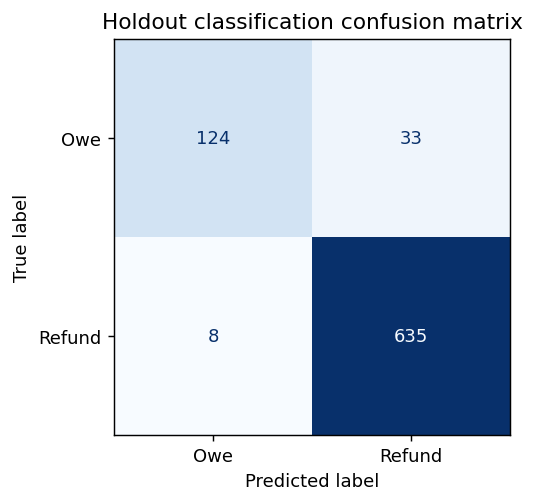

In [9]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(yc_test,clf_pred,display_labels=['Owe','Refund'],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Holdout classification confusion matrix')
save_chart('07_confusion_matrix.png')

## 7. Retrain on all labeled data and predict new examples
After final holdout evaluation, refit the selected models on all synthetic records. These example predictions are illustrative, **not tax estimates**.

### Line-by-line explanation of the following Python cell

This commentary explains each nonblank code line; the original executable code and its saved outputs remain unchanged.

| Line | Python statement | Explanation |
|---:|---|---|
| 1 | `final_reg=Pipeline([('preprocess',preprocessing()),('model',regressors[best_reg_name])])` | Builds a sequence of preprocessing and modeling operations. |
| 2 | `final_clf=Pipeline([('preprocess',preprocessing()),('model',classifiers[best_clf_name])])` | Builds a sequence of preprocessing and modeling operations. |
| 3 | `final_reg.fit(X,y_reg)` | Fits the model to the specified training data. |
| 4 | `final_clf.fit(X,y_clf)` | Fits the model to the specified training data. |
| 5 | `new_taxpayers=pd.DataFrame([` | Creates a pandas table from the supplied records or arrays. |
| 6 | `{'annual_income':55000,'other_income':0,'filing_status':'Single','dependents':0,'additional_deductions':1000,'tax_withheld':6500},` | Defines a named field, model, or setting in a collection. |
| 7 | `{'annual_income':98000,'other_income':3000,'filing_status':'Married filing jointly','dependents':2,'additional_deductions':3500,'tax_withheld':12000},` | Defines a named field, model, or setting in a collection. |
| 8 | `{'annual_income':74000,'other_income':1000,'filing_status':'Head of household','dependents':1,'additional_deductions':2200,'tax_withheld':7600}` | Continues the preceding expression or configuration. |
| 9 | `])` | Closes the preceding data structure or function call. |
| 10 | `results=new_taxpayers.copy()` | Assigns or updates `results` for use in subsequent steps. |
| 11 | `results['predicted_net_refund_dollars']=final_reg.predict(new_taxpayers).round(2)` | Generates model predictions. |
| 12 | `results['predicted_outcome']=np.where(final_clf.predict(new_taxpayers)==1,'Refund','Owe')` | Generates model predictions. |
| 13 | `results['probability_refund']=final_clf.predict_proba(new_taxpayers)[:,1].round(3)` | Calculates class probability estimates. |
| 14 | `display(results)` | Displays a table or image in the notebook. |
| 15 | `results.to_csv(OUTPUT/'example_tax_predictions.csv',index=False)` | Exports results as a CSV file. |
| 16 | `print('Saved outputs to:',OUTPUT.resolve())` | Prints a result or diagnostic message. |


In [10]:
final_reg=Pipeline([('preprocess',preprocessing()),('model',regressors[best_reg_name])])
final_clf=Pipeline([('preprocess',preprocessing()),('model',classifiers[best_clf_name])])
final_reg.fit(X,y_reg)
final_clf.fit(X,y_clf)
new_taxpayers=pd.DataFrame([
    {'annual_income':55000,'other_income':0,'filing_status':'Single','dependents':0,'additional_deductions':1000,'tax_withheld':6500},
    {'annual_income':98000,'other_income':3000,'filing_status':'Married filing jointly','dependents':2,'additional_deductions':3500,'tax_withheld':12000},
    {'annual_income':74000,'other_income':1000,'filing_status':'Head of household','dependents':1,'additional_deductions':2200,'tax_withheld':7600}
])
results=new_taxpayers.copy()
results['predicted_net_refund_dollars']=final_reg.predict(new_taxpayers).round(2)
results['predicted_outcome']=np.where(final_clf.predict(new_taxpayers)==1,'Refund','Owe')
results['probability_refund']=final_clf.predict_proba(new_taxpayers)[:,1].round(3)
display(results)
results.to_csv(OUTPUT/'example_tax_predictions.csv',index=False)
print('Saved outputs to:',OUTPUT.resolve())

,annual_income,other_income,filing_status,dependents,additional_deductions,tax_withheld,predicted_net_refund_dollars,predicted_outcome,probability_refund
0,55000,0,Single,0,1000,6500,2328.74,Refund,0.899
1,98000,3000,Married filing jointly,2,3500,12000,4353.26,Refund,0.965
2,74000,1000,Head of household,1,2200,7600,2287.38,Refund,0.877


Saved outputs to: /mnt/data/tax_project_outputs


## 8. Interpretation, limitations, and responsible use

- **Synthetic-data limitation:** The labels come from a made-up mathematical formula. High test performance only shows the models learned that simulation; it does **not** establish accuracy on actual tax returns.
- **No IRS compliance:** Real taxes depend on tax year, federal/state jurisdiction, income types, eligibility rules, credits, phaseouts, and other information not represented here.
- **Leakage control:** No target-derived features are used, and preprocessing is fit inside each cross-validation fold.
- **Privacy:** Real financial data should be collected only with authorization, minimized, secured, and de-identified where appropriate.
- **Validation:** Before any real-world application, replace the synthetic data with permissioned, verified tax records; use temporal holdouts, subgroup error analysis, and independent tax-rule checks.


**References (background):** scikit-learn User Guide: https://scikit-learn.org/stable/user_guide.html ; IRS tax information: https://www.irs.gov/ .